# 🎬 Movie Profit Analysis

A simple exploratory data analysis (EDA) of ~3,400 movies, looking at **budgets, box-office earnings, genres, ratings and distributors**.

**Questions this notebook answers**
1. What does the data look like, and how clean is it?
2. How are budgets and box-office earnings distributed?
3. Which genres, MPAA ratings and distributors earn the most?
4. Does spending more money actually make a movie earn more?
5. Which movies were the most (and least) profitable?
6. How has the movie business changed over time?

**Tools:** Python, pandas, NumPy, Matplotlib

## 1. Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Make large numbers readable on charts (e.g. 1,500,000,000 -> $1.5B)
from matplotlib.ticker import FuncFormatter
def money(x, pos=None):
    if abs(x) >= 1e9: return f'${x/1e9:.1f}B'
    if abs(x) >= 1e6: return f'${x/1e6:.0f}M'
    if abs(x) >= 1e3: return f'${x/1e3:.0f}K'
    return f'${x:.0f}'
money_fmt = FuncFormatter(money)

# Show numbers without scientific notation in tables
pd.options.display.float_format = '{:,.2f}'.format
plt.rcParams['figure.figsize'] = (9, 5)

## 2. Load the Data
The dataset has one row per movie, with its release date, production budget, domestic (US) and worldwide gross, distributor, MPAA rating and genre.

In [3]:
data = pd.read_csv('data/movie_profit.csv')
data.tail()   # tail() shows the last 5 rows - the smallest-budget movies

,Unnamed: 0,release_date,movie,production_budget,domestic_gross,worldwide_gross,distributor,mpaa_rating,genre
3396,3397,10/28/2011,Like Crazy,"250,000.00","3,395,391.00","3,728,400.00",Paramount Pictures,PG-13,Drama
3397,3398,7/14/2000,Chuck&Buck,"250,000.00","1,055,671.00","1,157,672.00",Artisan,R,Drama
3398,3399,3/28/1997,Love and Other Catastrophes,"250,000.00","212,285.00","743,216.00",Fox Searchlight,R,Comedy
3399,3400,8/28/1998,I Married a Strange Person,"250,000.00","203,134.00","203,134.00",Lionsgate,NaN,Comedy
3400,3401,7/22/2005,November,"250,000.00","191,862.00","191,862.00",Sony Pictures Classics,R,Drama


In [4]:
data.columns

Index(['Unnamed: 0', 'release_date', 'movie', 'production_budget',
       'domestic_gross', 'worldwide_gross', 'distributor', 'mpaa_rating',
       'genre'],
      dtype='str')

## 3. Data Cleaning
Before analysing anything, we check for useless columns, missing values and duplicates.

The `Unnamed: 0` column is just the old index saved by whoever created the CSV. It carries no information, so we drop it.

In [5]:
data.drop(columns="Unnamed: 0", inplace=True)

In [6]:
data.info()   # column types and non-null counts

<class 'pandas.DataFrame'>
RangeIndex: 3401 entries, 0 to 3400
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   release_date       3401 non-null   str    
 1   movie              3401 non-null   str    
 2   production_budget  3401 non-null   float64
 3   domestic_gross     3401 non-null   float64
 4   worldwide_gross    3401 non-null   float64
 5   distributor        3353 non-null   str    
 6   mpaa_rating        3264 non-null   str    
 7   genre              3401 non-null   str    
dtypes: float64(3), str(5)
memory usage: 212.7 KB


In [7]:
print('Shape:', data.shape)
data.isnull().sum()   # missing values per column

Shape: (3401, 8)


release_date           0
movie                  0
production_budget      0
domestic_gross         0
worldwide_gross        0
distributor           48
mpaa_rating          137
genre                  0
dtype: int64

Only `distributor` (48 missing) and `mpaa_rating` (137 missing) have gaps. Together this affects fewer than 6% of rows, and we can't reliably guess a missing rating or distributor, so we drop those rows rather than fill them in.

In [8]:
rows_before = len(data)
data.dropna(inplace=True)
print(f'Dropped {rows_before - len(data)} rows ({(rows_before - len(data)) / rows_before:.1%}). Remaining: {len(data)}')
data.isnull().sum()

Dropped 171 rows (5.0%). Remaining: 3230


release_date         0
movie                0
production_budget    0
domestic_gross       0
worldwide_gross      0
distributor          0
mpaa_rating          0
genre                0
dtype: int64

In [9]:
data.duplicated().sum()   # 0 means no duplicate rows

np.int64(0)

### Fixing data types
`release_date` is stored as text. Converting it to a real date lets us extract the year and month later.

In [10]:
data['release_date'] = pd.to_datetime(data['release_date'], errors='coerce')
data['release_date'].isnull().sum()   # should be 0 if every date parsed correctly

np.int64(0)

### Movies with $0 gross
`describe()` below shows a minimum gross of **$0**. A movie that cost money to make and earned nothing is more likely a *missing* figure than a real result, so we count them before deciding what to do.

In [11]:
data.describe()

,release_date,production_budget,domestic_gross,worldwide_gross
count,3230,"3,230.00","3,230.00","3,230.00"
mean,2004-12-31 21:50:15.975232,"34,592,177.32","47,268,046.37","98,417,063.23"
min,1936-02-05 00:00:00,"250,000.00",0.00,0.00
25%,2000-03-01 12:00:00,"10,000,000.00","6,867,944.50","11,779,939.25"
50%,2006-02-17 00:00:00,"22,000,000.00","27,332,972.50","44,044,238.00"
75%,2011-09-16 00:00:00,"49,000,000.00","63,413,288.00","125,201,861.50"
max,2019-03-15 00:00:00,"175,000,000.00","474,544,677.00","1,304,866,322.00"
std,NaN,"35,263,374.90","59,737,068.47","143,284,086.63"


In [12]:
zero_ww = (data['worldwide_gross'] == 0).sum()
zero_dom = (data['domestic_gross'] == 0).sum()
print(f'Movies with $0 worldwide gross: {zero_ww}')
print(f'Movies with $0 domestic gross:  {zero_dom}')
data[data['worldwide_gross'] == 0].head()

Movies with $0 worldwide gross: 28
Movies with $0 domestic gross:  51


,release_date,movie,production_budget,domestic_gross,worldwide_gross,distributor,mpaa_rating,genre
30,2018-12-21,Aquaman,"160,000,000.00",0.00,0.00,Warner Bros.,PG-13,Action
228,2019-03-15,Wonder Park,"100,000,000.00",0.00,0.00,Paramount Pictures,PG,Adventure
1918,2014-08-22,The Prince,"18,000,000.00",0.00,0.00,Lionsgate,R,Action
2527,2012-04-13,Detention,"10,000,000.00",0.00,0.00,Samuel Goldwyn Films,R,Comedy
2528,2014-02-07,Nurse 3D,"10,000,000.00",0.00,0.00,Lionsgate,R,Horror


These rows would distort profit and ROI (they would look like a 100% loss). We keep the original `data` for the basic summaries, and create a `movies` table **without** zero-gross rows for the profit analysis in later sections.

In [13]:
movies = data[(data['worldwide_gross'] > 0) & (data['domestic_gross'] > 0)].copy()
print(f'Rows used for profit analysis: {len(movies)} of {len(data)}')

Rows used for profit analysis: 3179 of 3230


**What `describe()` tells us**
- The **average** budget is about **$34.6M**, but the **median** is only **$22M**. A few huge-budget blockbusters pull the average up.
- The same skew is stronger for earnings: average worldwide gross is about **$98M** but the median is **$44M**.
- The biggest budget in the data is **$175M**, and the biggest worldwide gross is about **$1.3B**.

## 4. Feature Engineering
We create a few new columns that make the analysis much more meaningful than raw gross alone.

In [14]:
# Profit = what the movie earned worldwide minus what it cost to make
movies['profit'] = movies['worldwide_gross'] - movies['production_budget']

# ROI (return on investment) = profit per dollar spent. 1.0 = doubled the money.
movies['roi'] = movies['profit'] / movies['production_budget']

# Was the movie profitable at all?
movies['is_profitable'] = movies['profit'] > 0

# Date parts for trend analysis
movies['release_year'] = movies['release_date'].dt.year
movies['release_month'] = movies['release_date'].dt.month
movies['decade'] = (movies['release_year'] // 10) * 10

movies[['movie', 'production_budget', 'worldwide_gross', 'profit', 'roi']].head()

,movie,production_budget,worldwide_gross,profit,roi
0,Evan Almighty,"175,000,000.00","174,131,329.00","-868,671.00",-0.00
1,Waterworld,"175,000,000.00","264,246,220.00","89,246,220.00",0.51
2,King Arthur: Legend of the Sword,"175,000,000.00","139,950,708.00","-35,049,292.00",-0.20
3,47 Ronin,"175,000,000.00","151,716,815.00","-23,283,185.00",-0.13
4,Jurassic World: Fallen Kingdom,"170,000,000.00","1,304,866,322.00","1,134,866,322.00",6.68


> **Note:** the budget is only an estimate of production cost. Marketing costs and the share of ticket sales kept by cinemas are not included, so real profits are lower than shown here.

## 5. Exploring the Data

### 5.1 Movies sorted by production budget

In [15]:
data.sort_values('production_budget', ascending=True).head(10)   # cheapest films

,release_date,movie,production_budget,domestic_gross,worldwide_gross,distributor,mpaa_rating,genre
3400,2005-07-22,November,"250,000.00","191,862.00","191,862.00",Sony Pictures Classics,R,Drama
3398,1997-03-28,Love and Other Catastrophes,"250,000.00","212,285.00","743,216.00",Fox Searchlight,R,Comedy
3397,2000-07-14,Chuck&Buck,"250,000.00","1,055,671.00","1,157,672.00",Artisan,R,Drama
3396,2011-10-28,Like Crazy,"250,000.00","3,395,391.00","3,728,400.00",Paramount Pictures,PG-13,Drama
3395,2003-04-11,Better Luck Tomorrow,"250,000.00","3,802,390.00","3,809,226.00",Paramount Pictures,R,Drama
3394,2017-04-28,Sleight,"250,000.00","3,930,990.00","3,934,450.00",High Top Releasing,R,Action
3393,2002-06-28,Lovely and Amazing,"250,000.00","4,210,379.00","4,613,482.00",Lionsgate,R,Drama
3392,2012-08-17,Compliance,"270,000.00","319,285.00","830,700.00",Magnolia Pictures,R,Drama
3390,1998-08-07,"First Love, Last Rites","300,000.00","10,876.00","10,876.00",Strand,R,Drama
3388,2005-07-15,First Morning,"300,000.00","87,264.00","87,264.00",Illuminare,PG-13,Drama


In [16]:
data.sort_values('production_budget', ascending=False).head(10)  # most expensive films

,release_date,movie,production_budget,domestic_gross,worldwide_gross,distributor,mpaa_rating,genre
0,2007-06-22,Evan Almighty,"175,000,000.00","100,289,690.00","174,131,329.00",Universal,PG,Comedy
1,1995-07-28,Waterworld,"175,000,000.00","88,246,220.00","264,246,220.00",Universal,PG-13,Action
2,2017-05-12,King Arthur: Legend of the Sword,"175,000,000.00","39,175,066.00","139,950,708.00",Warner Bros.,PG-13,Adventure
3,2013-12-25,47 Ronin,"175,000,000.00","38,362,475.00","151,716,815.00",Universal,PG-13,Action
4,2018-06-22,Jurassic World: Fallen Kingdom,"170,000,000.00","416,769,345.00","1,304,866,322.00",Universal,PG-13,Action
5,2014-08-01,Guardians of the Galaxy,"170,000,000.00","333,172,112.00","771,051,335.00",Walt Disney,PG-13,Action
6,2010-05-07,Iron Man 2,"170,000,000.00","312,433,331.00","621,156,389.00",Paramount Pictures,PG-13,Action
7,2014-04-04,Captain America: The Winter Soldier,"170,000,000.00","259,746,958.00","714,401,889.00",Walt Disney,PG-13,Action
8,2014-07-11,Dawn of the Planet of the Apes,"170,000,000.00","208,545,589.00","710,644,566.00",20th Century Fox,PG-13,Adventure
9,2004-11-10,The Polar Express,"170,000,000.00","186,493,587.00","310,634,169.00",Warner Bros.,G,Adventure


### 5.2 How many movies are in each genre?

In [17]:
data['genre'].value_counts()

genre
Drama        1180
Comedy        775
Action        540
Adventure     469
Horror        266
Name: count, dtype: int64

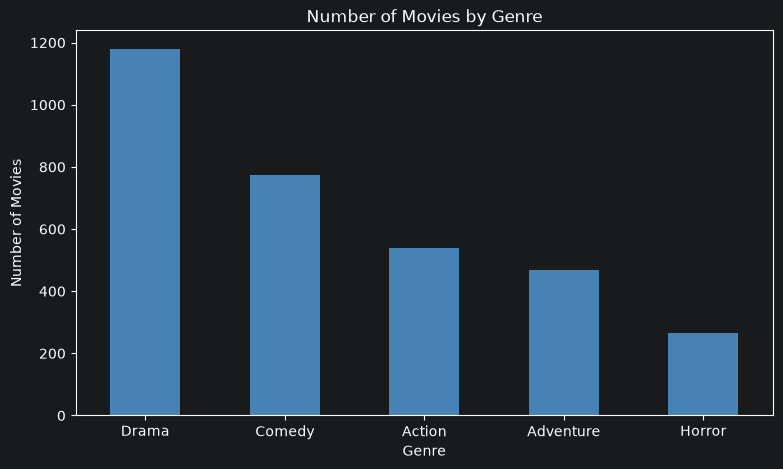

In [18]:
data['genre'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Number of Movies by Genre')
plt.xlabel('Genre')
plt.ylabel('Number of Movies')
plt.xticks(rotation=0)
plt.show()

**Finding:** **Drama** is the most common genre (1,180 movies), followed by **Comedy** (775) and **Action** (540). **Horror** is the least common (266).

### 5.3 Average budget by genre

In [19]:
data.groupby('genre')['production_budget'].mean().sort_values(ascending=False)

genre
Adventure   62,301,533.58
Action      58,503,125.72
Comedy      25,170,406.45
Drama       22,381,407.30
Horror      18,813,909.77
Name: production_budget, dtype: float64

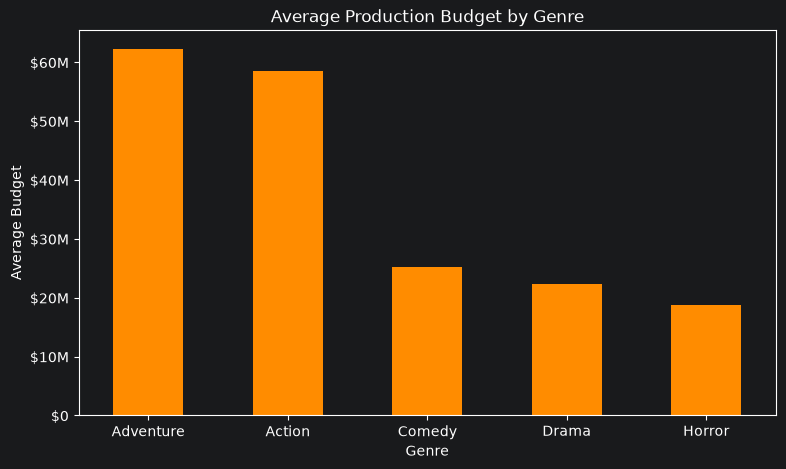

In [20]:
ax = data.groupby('genre')['production_budget'].mean().sort_values(ascending=False).plot(kind='bar', color='darkorange')
ax.yaxis.set_major_formatter(money_fmt)
plt.title('Average Production Budget by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Budget')
plt.xticks(rotation=0)
plt.show()

**Finding:** **Adventure** (about $62M) and **Action** (about $59M) movies cost more than twice as much to make as **Comedy** (about $25M), **Drama** (about $22M) and **Horror** (about $19M). Spectacle and special effects are expensive.

### 5.4 Distribution of worldwide gross

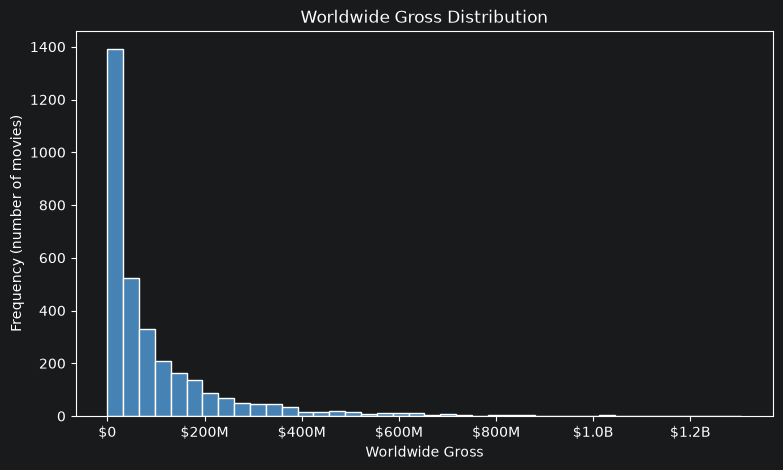

In [21]:
plt.hist(data['worldwide_gross'], bins=40, color='steelblue', edgecolor='white')
plt.gca().xaxis.set_major_formatter(money_fmt)
plt.title('Worldwide Gross Distribution')
plt.xlabel('Worldwide Gross')
plt.ylabel('Frequency (number of movies)')
plt.show()

**Finding:** The distribution is heavily **right-skewed**: most movies earn a modest amount and only a handful earn $500M+. This is why the median is a better "typical movie" measure than the mean.

### 5.5 Box office by MPAA rating

In [22]:
# How many movies per rating? Small groups make averages less reliable.
data['mpaa_rating'].value_counts()

mpaa_rating
R        1492
PG-13    1087
PG        567
G          84
Name: count, dtype: int64

In [23]:
data.groupby('mpaa_rating')['domestic_gross'].mean().sort_values(ascending=True)

mpaa_rating
R       32,085,290.33
PG-13   54,870,914.21
PG      67,420,108.74
G       82,531,562.19
Name: domestic_gross, dtype: float64

In [24]:
data.groupby('mpaa_rating')['domestic_gross'].median().sort_values(ascending=True)

mpaa_rating
R       15,934,642.00
PG-13   34,522,221.00
PG      48,006,762.00
G       58,611,764.50
Name: domestic_gross, dtype: float64

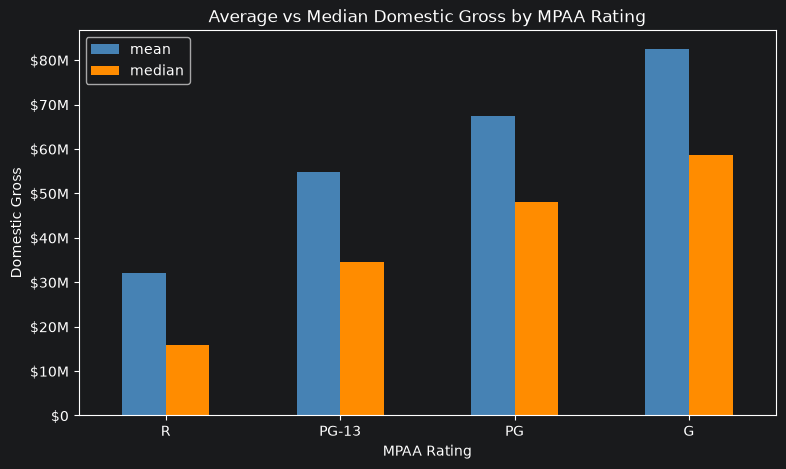

In [25]:
summary = data.groupby('mpaa_rating')['domestic_gross'].agg(['mean', 'median']).sort_values('median')
ax = summary.plot(kind='bar', color=['steelblue', 'darkorange'])
ax.yaxis.set_major_formatter(money_fmt)
plt.title('Average vs Median Domestic Gross by MPAA Rating')
plt.xlabel('MPAA Rating')
plt.ylabel('Domestic Gross')
plt.xticks(rotation=0)
plt.show()

**Finding:** Family-friendly ratings earn the most per movie: **G** movies average about **$82.5M** domestically, and **R** movies the least at about **$32.1M**. The median tells the same story (G about $58.6M vs R about $15.9M). Broader audiences mean more tickets sold.

⚠️ **Caution:** check the counts above. If very few movies are rated G, that average rests on a small sample.

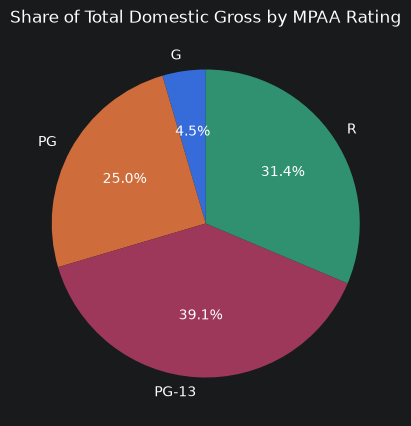

In [26]:
data.groupby('mpaa_rating')['domestic_gross'].sum().plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Share of Total Domestic Gross by MPAA Rating')
plt.ylabel('')
plt.show()

**Finding:** Even though R-rated movies earn the least *per movie*, there are so many of them that they and **PG-13** movies take the biggest share of the *total* domestic box office.

### 5.6 Budget vs worldwide gross

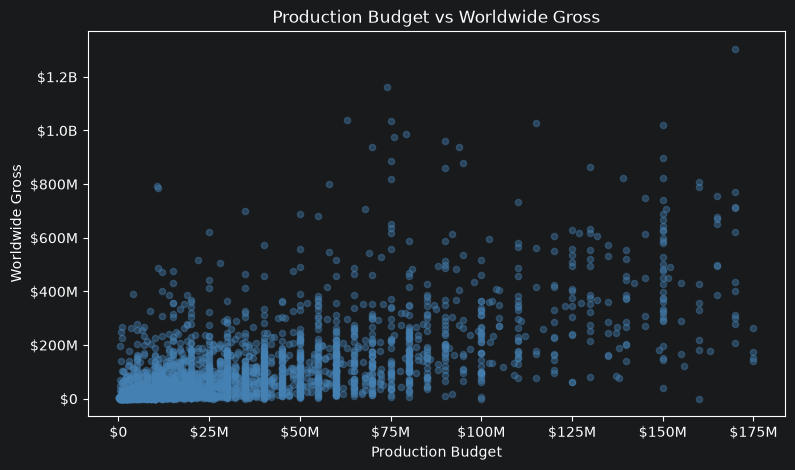

In [27]:
data.plot(kind='scatter', x='production_budget', y='worldwide_gross', alpha=0.4, color='steelblue')
plt.gca().xaxis.set_major_formatter(money_fmt)
plt.gca().yaxis.set_major_formatter(money_fmt)
plt.title('Production Budget vs Worldwide Gross')
plt.xlabel('Production Budget')
plt.ylabel('Worldwide Gross')
plt.show()

In [28]:
corr = data['production_budget'].corr(data['worldwide_gross'])
print(f'Correlation between budget and worldwide gross: {corr:.2f}')

Correlation between budget and worldwide gross: 0.65


**Finding:** There is a clear **positive relationship**: bigger budgets tend to earn more. But the spread widens as budgets grow, meaning big spending also brings big risk: some $100M+ movies earn far less than they cost. A big budget does **not** guarantee success.

### 5.7 Distributors

In [29]:
data.groupby('distributor')['worldwide_gross'].sum().sort_values(ascending=False).head(10)

distributor
Warner Bros.         48,216,137,302.00
20th Century Fox     46,973,838,322.00
Universal            45,996,465,584.00
Sony Pictures        37,470,756,903.00
Paramount Pictures   37,321,928,189.00
Walt Disney          35,245,927,709.00
Lionsgate             9,206,507,171.00
MGM                   7,591,127,052.00
Dreamworks SKG        7,092,695,984.00
New Line              6,114,452,445.00
Name: worldwide_gross, dtype: float64

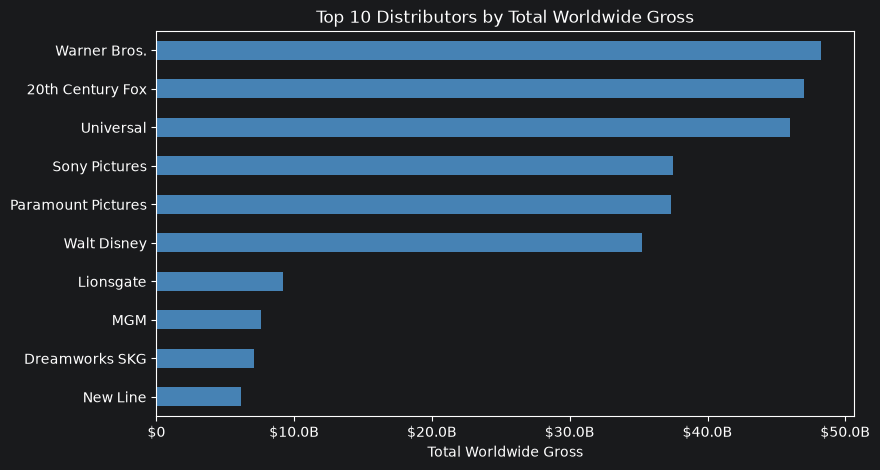

In [30]:
top10 = data.groupby('distributor')['worldwide_gross'].sum().sort_values(ascending=False).head(10)
ax = top10.sort_values().plot(kind='barh', color='steelblue')
ax.xaxis.set_major_formatter(money_fmt)
plt.title('Top 10 Distributors by Total Worldwide Gross')
plt.xlabel('Total Worldwide Gross')
plt.ylabel('')
plt.show()

**Finding:** The big studios dominate: **Warner Bros.** (about $48.2B), **20th Century Fox** (about $47.0B) and **Universal** (about $46.0B) lead, followed by **Sony Pictures** and **Paramount**. Many small distributors earned little or nothing.

The original notebook averaged domestic gross for the first 5 distributors in alphabetical order, which is an arbitrary choice. A fairer view: the top 10 distributors by number of movies released, with a minimum of 20 films so averages are reliable.

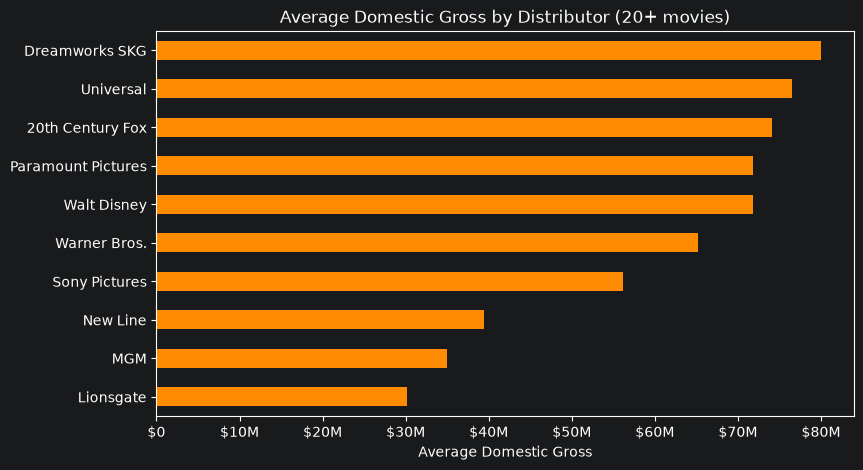

,count,mean
distributor,,
Dreamworks SKG,44,"79,974,412.39"
Universal,283,"76,555,561.57"
20th Century Fox,272,"74,050,804.17"
Paramount Pictures,257,"71,852,868.64"
Walt Disney,239,"71,787,871.69"
Warner Bros.,363,"65,208,874.66"
Sony Pictures,333,"56,176,973.39"
New Line,99,"39,429,100.73"
MGM,109,"34,970,504.52"


In [31]:
dist = data.groupby('distributor')['domestic_gross'].agg(['count', 'mean'])
dist = dist[dist['count'] >= 20].sort_values('mean', ascending=False).head(10)
ax = dist['mean'].sort_values().plot(kind='barh', color='darkorange')
ax.xaxis.set_major_formatter(money_fmt)
plt.title('Average Domestic Gross by Distributor (20+ movies)')
plt.xlabel('Average Domestic Gross')
plt.ylabel('')
plt.show()
dist

## 6. Profit & ROI Analysis
Gross earnings ignore cost. Here we look at what movies actually *made* after their budget.

### 6.1 How many movies made money?

70.5% of movies earned more worldwide than their production budget.


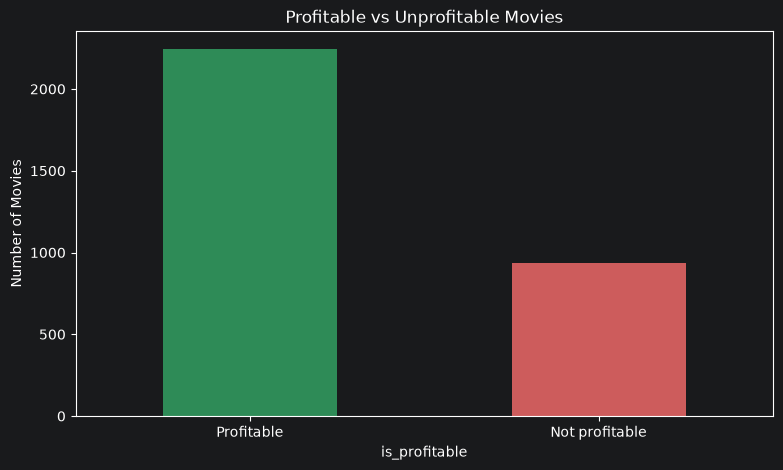

In [32]:
share = movies['is_profitable'].mean()
print(f'{share:.1%} of movies earned more worldwide than their production budget.')
movies['is_profitable'].value_counts().plot(kind='bar', color=['seagreen', 'indianred'])
plt.title('Profitable vs Unprofitable Movies')
plt.xticks([0, 1], ['Profitable', 'Not profitable'], rotation=0)
plt.ylabel('Number of Movies')
plt.show()

### 6.2 Top 10 most profitable movies

In [33]:
movies.nlargest(10, 'profit')[['movie', 'release_year', 'genre', 'production_budget', 'worldwide_gross', 'profit']]

,movie,release_year,genre,production_budget,worldwide_gross,profit
4,Jurassic World: Fallen Kingdom,2018,Action,"170,000,000.00","1,304,866,322.00","1,134,866,322.00"
426,Minions,2015,Adventure,"74,000,000.00","1,162,781,621.00","1,088,781,621.00"
545,Jurassic Park,1993,Action,"63,000,000.00","1,038,812,584.00","975,812,584.00"
392,Despicable Me 3,2017,Adventure,"75,000,000.00","1,034,520,868.00","959,520,868.00"
149,Star Wars Ep. I: The Phantom Menace,1999,Adventure,"115,000,000.00","1,027,044,677.00","912,044,677.00"
380,The Lion King,1994,Adventure,"79,300,000.00","986,332,275.00","907,032,275.00"
387,Despicable Me 2,2013,Adventure,"76,000,000.00","975,216,835.00","899,216,835.00"
253,Jumanji: Welcome to the Jungle,2017,Adventure,"90,000,000.00","961,758,540.00","871,758,540.00"
39,Zootopia,2016,Adventure,"150,000,000.00","1,019,706,594.00","869,706,594.00"
440,Shrek 2,2004,Adventure,"70,000,000.00","937,008,132.00","867,008,132.00"


### 6.3 Top 10 biggest losses

In [34]:
movies.nsmallest(10, 'profit')[['movie', 'release_year', 'genre', 'production_budget', 'worldwide_gross', 'profit']]

,movie,release_year,genre,production_budget,worldwide_gross,profit
69,Mars Needs Moms,2011,Adventure,"150,000,000.00","39,549,758.00","-110,450,242.00"
226,The Adventures of Pluto Nash,2002,Comedy,"100,000,000.00","7,094,995.00","-92,905,005.00"
281,The Promise,2017,Drama,"90,000,000.00","10,551,417.00","-79,448,583.00"
379,A Sound of Thunder,2005,Action,"80,000,000.00","6,300,451.00","-73,699,549.00"
251,Cutthroat Island,1995,Adventure,"92,000,000.00","18,517,322.00","-73,482,678.00"
425,Monkeybone,2001,Comedy,"75,000,000.00","5,409,517.00","-69,590,483.00"
132,Monster Trucks,2017,Adventure,"125,000,000.00","61,642,798.00","-63,357,202.00"
133,The 13th Warrior,1999,Action,"125,000,000.00","61,698,899.00","-63,301,101.00"
91,Stealth,2005,Action,"138,000,000.00","76,416,746.00","-61,583,254.00"
423,Soldier,1998,Action,"75,000,000.00","14,623,082.00","-60,376,918.00"


### 6.4 Which genre is the best investment?

In [35]:
genre_stats = movies.groupby('genre').agg(
    movies=('movie', 'count'),
    avg_budget=('production_budget', 'mean'),
    avg_profit=('profit', 'mean'),
    median_roi=('roi', 'median'),
    pct_profitable=('is_profitable', 'mean')
).sort_values('median_roi', ascending=False)
genre_stats['pct_profitable'] = (genre_stats['pct_profitable'] * 100).round(1)
genre_stats

,movies,avg_budget,avg_profit,median_roi,pct_profitable
genre,,,,,
Horror,260,"19,156,538.46","56,199,439.93",1.80,78.80
Adventure,460,"63,103,085.32","145,610,310.01",1.55,82.60
Action,529,"59,211,319.26","101,008,210.11",1.26,76.70
Comedy,765,"25,409,235.29","42,859,550.92",0.93,69.30
Drama,1165,"22,537,906.10","33,480,823.17",0.59,61.90


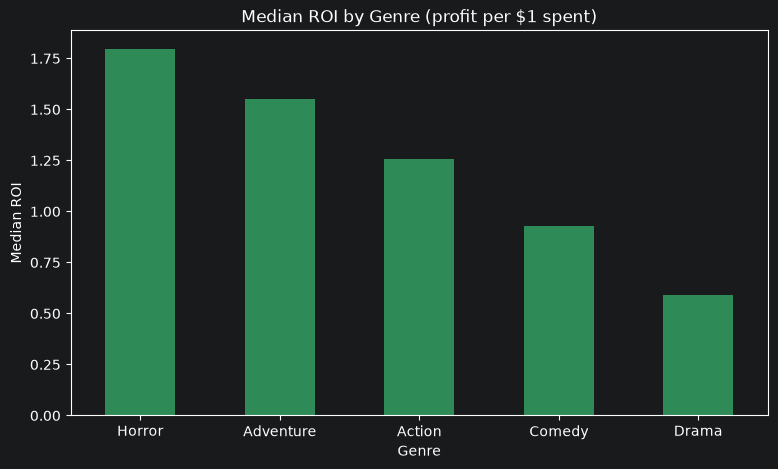

In [36]:
ax = genre_stats['median_roi'].plot(kind='bar', color='seagreen')
plt.title('Median ROI by Genre (profit per $1 spent)')
plt.xlabel('Genre')
plt.ylabel('Median ROI')
plt.xticks(rotation=0)
plt.show()

We use the **median** ROI instead of the mean because a few movies with enormous returns (very cheap films that became hits) would otherwise dominate the average.

### 6.5 Does the rating affect profitability?

In [37]:
rating_stats = movies.groupby('mpaa_rating').agg(
    movies=('movie', 'count'),
    median_roi=('roi', 'median'),
    pct_profitable=('is_profitable', 'mean')
)
rating_stats['pct_profitable'] = (rating_stats['pct_profitable'] * 100).round(1)
rating_stats.sort_values('median_roi', ascending=False)

,movies,median_roi,pct_profitable
mpaa_rating,,,
G,84,2.59,85.70
PG,558,1.37,78.00
PG-13,1075,1.03,71.10
R,1462,0.84,66.40


## 7. Trends Over Time

### 7.1 Movies released per decade

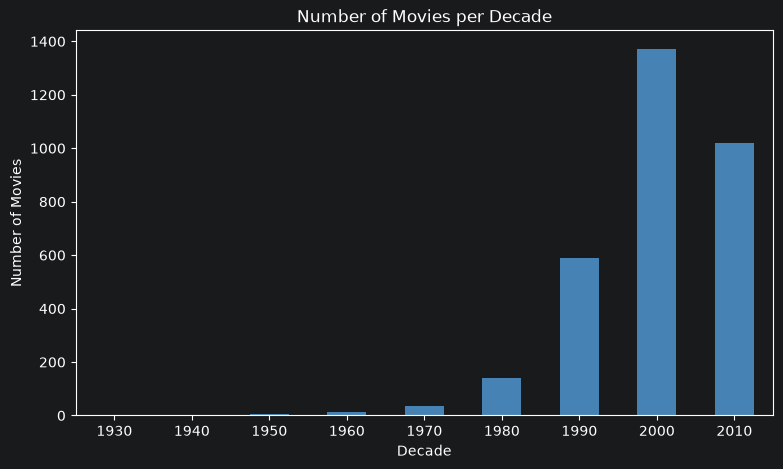

In [38]:
movies['decade'].value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Number of Movies per Decade')
plt.xlabel('Decade')
plt.ylabel('Number of Movies')
plt.xticks(rotation=0)
plt.show()

### 7.2 Are budgets growing?

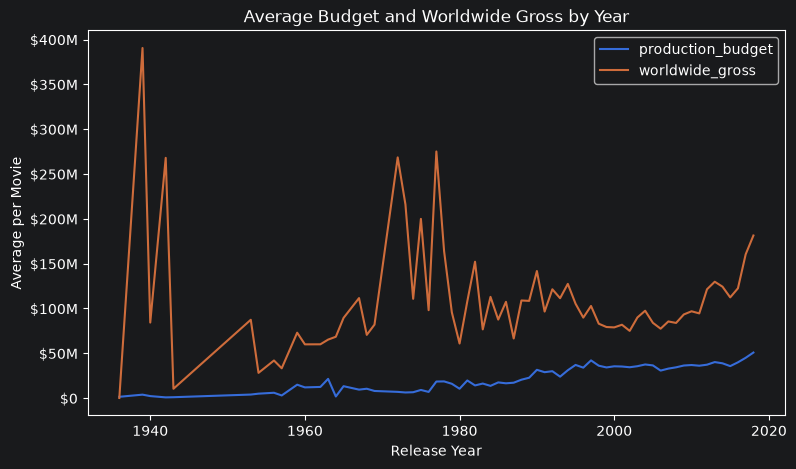

In [39]:
yearly = movies.groupby('release_year')[['production_budget', 'worldwide_gross']].mean()
ax = yearly.plot()
ax.yaxis.set_major_formatter(money_fmt)
plt.title('Average Budget and Worldwide Gross by Year')
plt.xlabel('Release Year')
plt.ylabel('Average per Movie')
plt.show()

> Money values are **not adjusted for inflation**, so some of the growth over the years is simply prices going up.

### 7.3 Best months to release a movie

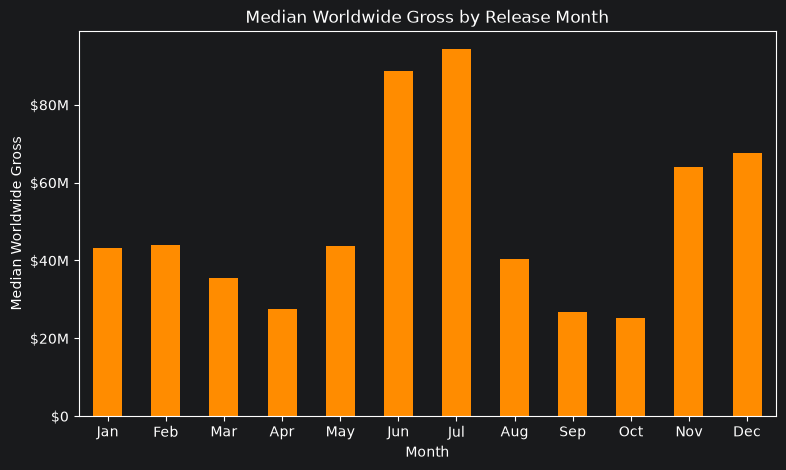

In [40]:
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
monthly = movies.groupby('release_month')['worldwide_gross'].median()
monthly.index = [month_names[m - 1] for m in monthly.index]
ax = monthly.plot(kind='bar', color='darkorange')
ax.yaxis.set_major_formatter(money_fmt)
plt.title('Median Worldwide Gross by Release Month')
plt.xlabel('Month')
plt.ylabel('Median Worldwide Gross')
plt.xticks(rotation=0)
plt.show()

Summer (May-July) and the holiday season (November-December) are traditionally the biggest movie periods, because school is out and people have time off. The chart shows whether this data agrees.

## 8. Summary of Findings

In [42]:
# Key numbers calculated directly from the data, so they always match the analysis above
best_roi_genre = genre_stats['median_roi'].idxmax()
top_genre = data['genre'].value_counts().idxmax()
best_month = monthly.idxmax()
best_decade = movies.groupby('decade')['profit'].mean().idxmax()
top_profit = movies.loc[movies['profit'].idxmax()]

print(f'• Dataset: {len(data):,} movies after cleaning ({len(movies):,} used for profit analysis)')
print(f'• Most common genre: {top_genre}')
print(f'• {movies["is_profitable"].mean():.0%} of movies made back their production budget')
print(f'• Best median ROI by genre: {best_roi_genre} ({genre_stats.loc[best_roi_genre, "median_roi"]:.2f}x)')
print(f'• Most profitable movie: {top_profit["movie"]} (${top_profit["profit"]/1e6:,.0f}M profit)')
print(f'• Best release month by median gross: {best_month}')
print(f'• Decade with highest average profit: {int(best_decade)}s')
print(f'• Budget vs worldwide gross correlation: {corr:.2f}')

• Dataset: 3,230 movies after cleaning (3,179 used for profit analysis)
• Most common genre: Drama
• 71% of movies made back their production budget
• Best median ROI by genre: Horror (1.80x)
• Most profitable movie: Jurassic World: Fallen Kingdom ($1,135M profit)
• Best release month by median gross: Jul
• Decade with highest average profit: 1930s
• Budget vs worldwide gross correlation: 0.65


### Key takeaways
1. **Most movies are not blockbusters.** Typical earnings (median) are far below the average, and a small number of hits drive most of the money.
2. **Action and Adventure movies cost the most** to produce, while Drama, Comedy and Horror are made on much smaller budgets.
3. **Family-friendly ratings (G, PG) earn more per movie** than R-rated films, although R and PG-13 movies make up the biggest share of total earnings because there are so many of them.
4. **Bigger budgets earn more on average, but with more risk.** Spending does not guarantee profit.
5. **A handful of major studios** (Warner Bros., 20th Century Fox, Universal, Sony, Paramount) account for most of the worldwide box office.

### Limitations
- Budgets exclude marketing and distribution costs, so real profit is lower.
- Money is not adjusted for inflation, which affects comparisons across decades.
- Only 5 genres and 4 ratings appear, and movies with missing ratings or distributors (about 5%) were removed.
- This is exploratory analysis: it shows relationships, not causes.

### Possible next steps
- Adjust all values for inflation.
- Add IMDb or Rotten Tomatoes ratings to see if quality affects earnings.
- Build a simple model to predict a movie's worldwide gross from its budget, genre and rating.